# 02 · Exploratory analysis: rare-earth imports from China and wind power

**Assignment 5, steps 2–4.** Univariate, bivariate and multivariate analysis, plus hypothesis testing, of the Assignment 4 database.
Functions live in [`src/analysis/`](../src/analysis/): `exploratory.py` (loading, describing),
`statistical.py` (correlation, partial correlation, regression) and `charts.py` (figures).

**Business question:** does the build-out of wind power drive countries' demand for Chinese rare earths,
and how exposed are buyers to a concentrated supplier?

Charts are saved to `docs/figures/` only when the notebook runs on the real database.

In [1]:
from functools import partial

import pandas as pd
from IPython.display import display

from src.analysis import charts as ch
from src.analysis import exploratory as ex
from src.analysis import statistical as st

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
con, db_path = ex.open_database()   # real database, or the synthetic sample if it isn't built
IS_REAL = db_path == ex.REAL_DB
print(f"Connected to {db_path.name} ({'real data' if IS_REAL else 'SYNTHETIC SAMPLE: numbers are fake'})")

trade = ex.load_trade(con)          # every trade row + partner power mix
panel = ex.load_country_panel(con)  # country x year: imports, growth, wind, size
wind = ex.load_wind(con)            # wind generation and capacity, all countries
sample = ex.analysis_sample(panel)  # country-years usable for multivariate analysis
SOURCE = "Source: China HS 284690 trade (data1.xlsx); Ember yearly electricity data (data2.xlsx)"
show = partial(ch.show, save_figure=IS_REAL)  # charts saved to docs/figures/ only from real data

Connected to rare_earth.db (real data)


---
## 1. Univariate analysis

### 1.1 Summary statistics (2024, one row per country)

In [2]:
cols = ["imports_from_china_kg", "import_growth_pct", "wind_capacity_gw",
        "wind_generation_twh", "total_generation_twh", "wind_share_pct"]
ex.describe_numeric(panel[panel["year"] == 2024], cols)

,n,missing,missing_pct,mean,median,std,min,max,skew
column,,,,,,,,,
imports_from_china_kg,60,12,16.70,"588,413.77","9,307.50","1,996,861.10",3.75,"12,517,000.00",4.67
import_growth_pct,52,20,27.80,"11,367.87",21.23,"77,301.47",-93.75,"557,690.00",6.99
wind_capacity_gw,66,6,8.30,8.86,1.41,21.95,0.00,152.65,4.86
wind_generation_twh,67,5,6.90,21.50,3.17,59.68,0.00,451.90,5.90
total_generation_twh,68,4,5.60,278.76,88.95,603.07,1.64,"4,391.02",5.20
wind_share_pct,67,5,6.90,8.01,3.75,10.46,0.00,58.38,2.21


Every size measure has a **skew of 4–7**: a handful of countries are far larger than the rest, so the
mean is far above the median. Analysis below therefore uses **medians, rank (Spearman) correlation and
log scales**.

In [3]:
imports_2024 = panel.loc[panel["year"] == 2024, "imports_from_china_kg"]
pd.DataFrame([st.normality_test(imports_2024), st.normality_test(imports_2024, log=True)])

,test,scale,n,statistic,p,skew,normal
0,Shapiro-Wilk,raw,60,0.33,0.00,4.67,False
1,Shapiro-Wilk,log10,60,0.98,0.62,0.04,True


**Normality check (Shapiro-Wilk).** Raw imports are far from normal, but their log10 values
are consistent with a normal distribution. That justifies log-scale correlation and regression in
sections 3–4, and rank-based tests where logs aren't used.

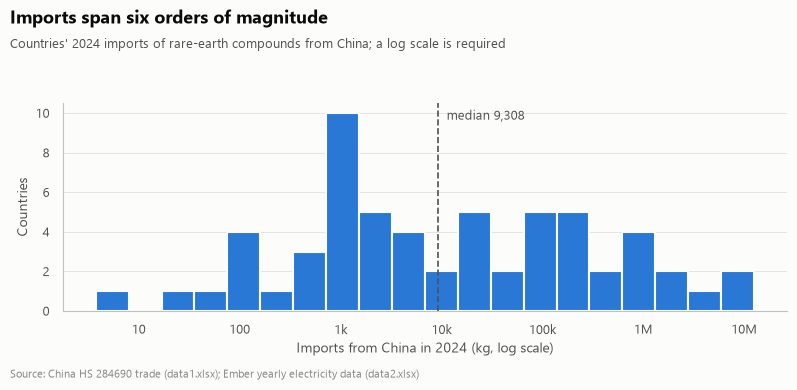

In [4]:
fig = ch.log_histogram(
    panel.loc[panel["year"] == 2024, "imports_from_china_kg"],
    "Imports from China in 2024 (kg, log scale)",
    "Imports span six orders of magnitude",
    "Countries' 2024 imports of rare-earth compounds from China; a log scale is required", SOURCE)
show(fig, "06_distribution")

### 1.2 Import growth, 2024

In [5]:
growth = st.growth_summary(panel.loc[panel["year"] == 2024, "import_growth_pct"])
pd.Series(growth).to_frame("2024 import growth")

,2024 import growth
n,52.00
median_pct,21.23
q1_pct,-48.63
q3_pct,181.39
share_growing,0.56
extreme_count,9.00
mean_pct,"11,367.87"


Growth rates from tiny bases explode: the **mean** is in the thousands of percent while the **median**
is modest. Growth should be modelled as a **log ratio** (`log(this year / last year)`) or winsorized,
never averaged raw.

### 1.3 Unit values (price per kg)

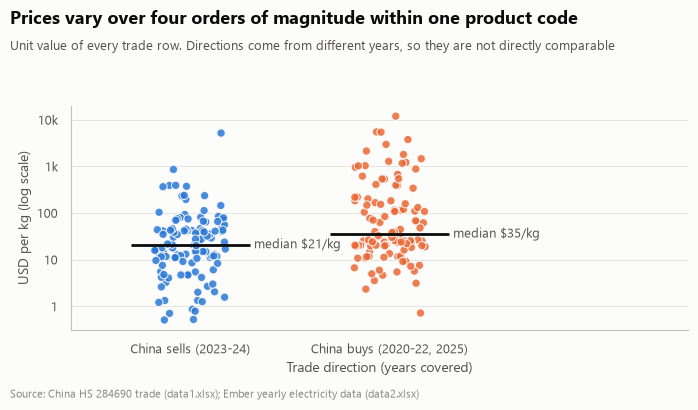

In [6]:
fig = ch.group_strip(
    trade, "unit_value_usd_per_kg", "trade_flow", ["Export", "Import"], "USD per kg (log scale)",
    "Prices vary over four orders of magnitude within one product code",
    "Unit value of every trade row. Directions come from different years, so they are not directly comparable",
    SOURCE, tick_labels=["China sells (2023-24)", "China buys (2020-22, 2025)"],
    xlabel="Trade direction (years covered)")
show(fig, "07_unit_values")

HS 284690 bundles many rare-earth compounds, from cheap bulk oxides to costly separated elements, so
**price per kg varies from under $1 to over $10,000**. Quantity in kg is therefore a better
measure of physical demand than value. The direction medians differ, but they come from different years,
so no conclusion about direction is drawn.

### 1.4 The regression sample (Table 1)

The tables above describe every country in 2024. The models in sections 3 and 4 use the **regression
sample**: country-years with imports, wind capacity and total generation all recorded and positive.
This is its descriptive table, on the raw scale and on the log10 scale the models use.

In [7]:
model_vars = {"imports_from_china_kg": "Imports from China (kg)", "wind_capacity_gw": "Wind capacity (GW)",
              "total_generation_twh": "Total generation (TWh)", "wind_share_pct": "Wind share of generation (%)"}
years = sample["year"].value_counts().sort_index()
print(f"Regression sample: {len(sample)} country-years, {sample['country'].nunique()} countries "
      f"({', '.join(f'{y}: {n}' for y, n in years.items())})")
st.descriptive_table(sample, list(model_vars), log_columns=list(model_vars)[:3], labels=model_vars)

Regression sample: 102 country-years, 58 countries (2023: 51, 2024: 51)


,n,mean,sd,min,p25,median,p75,max,skew,shapiro_p,normal
variable,,,,,,,,,,,
Imports from China (kg),102,"591,605.97","1,968,168.67",2.00,727.00,"5,253.50","150,915.75","12,517,000.00",4.64,0.00,False
log10 Imports from China (kg),102,3.94,1.57,0.30,2.86,3.72,5.18,7.10,0.03,0.16,True
Wind capacity (GW),102,11.00,23.86,0.03,0.36,3.27,10.64,152.65,4.32,0.00,False
log10 Wind capacity (GW),102,0.34,0.89,-1.52,-0.44,0.51,1.03,2.18,-0.17,0.04,False
Total generation (TWh),102,347.16,664.92,4.52,70.30,152.12,335.87,"4,391.02",4.57,0.00,False
log10 Total generation (TWh),102,2.14,0.62,0.66,1.85,2.18,2.53,3.64,-0.23,0.22,True
Wind share of generation (%),102,9.01,9.73,0.00,1.17,5.89,12.11,57.21,1.77,0.00,False


In [8]:
# Pearson correlations of the log10 values: the associations the log-log regressions work with
st.correlation_matrix(sample, list(model_vars)[:3], method="pearson", log=True).rename(
    index=model_vars, columns=model_vars)

,Imports from China (kg),Wind capacity (GW),Total generation (TWh)
Imports from China (kg),1.00,0.53,0.76
Wind capacity (GW),0.53,1.00,0.61
Total generation (TWh),0.76,0.61,1.00


**What Table 1 shows, and how it shapes the analysis**
1. **The raw variables are extremely skewed** (skew 4–5). The mean of imports is over 100 times the
   median, because a few very large buyers pull it up. So the data are described with **medians**.
2. **Logs remove the skew.** On the log10 scale every skew is close to 0, and imports and size pass
   Shapiro-Wilk. Log wind capacity fails narrowly, which doesn't matter for OLS: it needs normal
   **residuals**, not normal predictors, and Model B's residuals are normal (3.2). This justifies
   **log-log OLS**.
3. **The correlations show the confounding before any test.** Size is more closely linked to imports
   (r = 0.76) than wind is (0.53), and wind and size are linked to each other (0.61). So wind's own
   effect can only be judged with size held fixed (H2). Each of these pairs has a scatter in the pair
   plot (2.4).

---
## 2. Bivariate analysis

### 2.1 Who buys from China? Concentration of demand

,2024
countries,60
top1_share,0.35
top5_share,0.83
top10_share,0.94
hhi,2054
level,highly concentrated


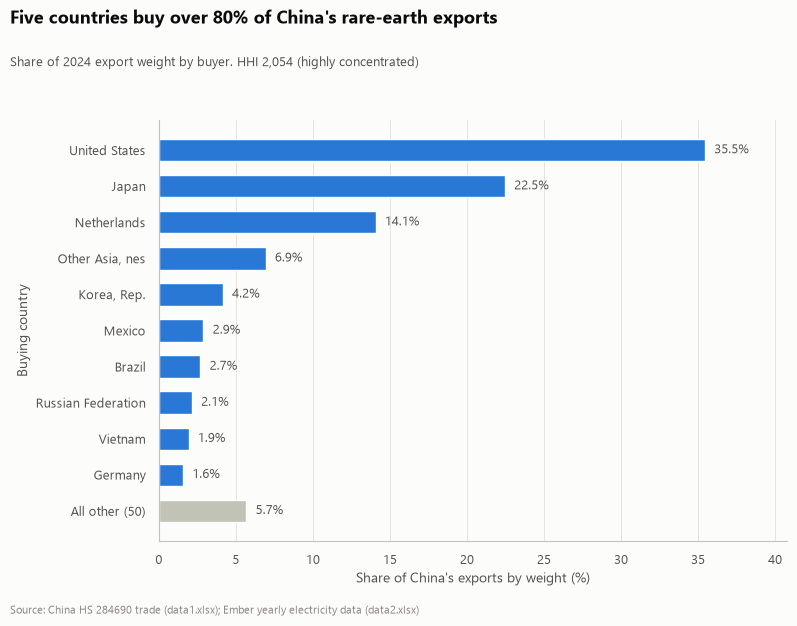

In [9]:
exports_2024 = trade[(trade["trade_flow"] == "Export") & (trade["year"] == 2024)]
conc = ex.concentration(ex.buyer_volumes(trade, 2024))
shares = ex.market_shares(exports_2024, "partner", "quantity_kg", top=10)
display(pd.Series(conc).to_frame("2024"))
fig = ch.market_share_bars(
    shares, "Five countries buy over 80% of China's rare-earth exports",
    f"Share of 2024 export weight by buyer. HHI {conc['hhi']:,} ({conc['level']})", SOURCE)
show(fig, "01_concentration")

### 2.2 Volume vs value over time

,year,trade_flow,partners,quantity_kg,value_kusd,unit_value_usd_per_kg
0,2020,Import,25,"42,260,820.18","494,061.12",11.69
1,2021,Import,26,"44,752,941.07","1,063,323.65",23.76
2,2022,Import,25,"42,095,015.17","1,057,416.69",25.12
3,2023,Export,60,"33,392,492.55","512,019.29",15.33
4,2024,Export,60,"35,304,826.15","377,003.25",10.68
5,2025,Import,31,"75,888,981.83","1,550,090.05",20.43


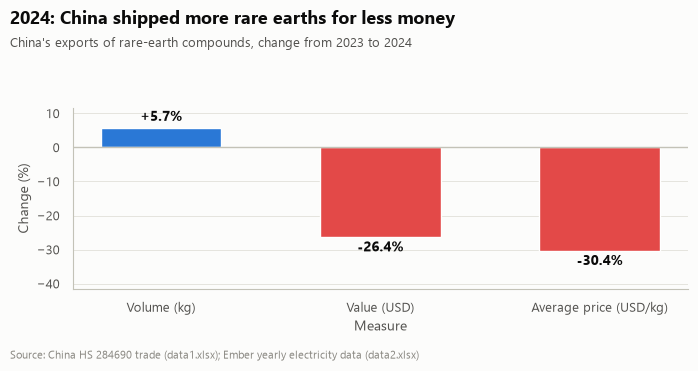

In [10]:
yearly = ex.yearly_trade(trade)
display(yearly)
change = ex.period_change(yearly, "Export", 2023, 2024)
change.index = ["Volume (kg)", "Value (USD)", "Average price (USD/kg)"]
fig = ch.change_bars(change, "2024: China shipped more rare earths for less money",
                     "China's exports of rare-earth compounds, change from 2023 to 2024", SOURCE)
show(fig, "02_price_drop")

**Is the fall in the average price a real price cut, or a shift in who buys (mix)?** The average
price per kg can fall because buyers pay less, or because more of the volume goes to buyers who pay less.
A fixed-basket price index separates the two: it prices each buyer's 2023 volume at 2023 and at 2024
prices.

In [11]:
decomp = ex.price_mix_decomposition(trade, 2023, 2024)
display(pd.Series(decomp).to_frame("2023 to 2024"))
without_japan = ex.price_mix_decomposition(trade, 2023, 2024, exclude=["Japan"])
print(f"Fixed-basket price change without Japan: {without_japan['price_effect_pct']:+.1f}%")
ex.buyer_price_changes(trade, 2023, 2024).head(8)

,2023 to 2024
average_change_pct,-30.36
price_effect_pct,-34.84
mix_effect_pct,6.88
buyers,52.00
volume_covered,1.00
volume_share_price_fell,0.77


Fixed-basket price change without Japan: -14.3%


,kg_start,kg_end,price_start,price_end,price_change_pct,volume_share_start
partner,,,,,,
United States,"11,433,900.00","12,517,000.00",9.14,8.35,-8.70,0.34
"Other Asia, nes","5,140,190.00","2,446,470.00",2.01,2.68,33.75,0.15
Japan,"4,866,980.00","7,933,100.00",44.93,16.92,-62.35,0.15
Netherlands,"3,900,000.00","4,965,680.00",6.07,4.19,-31.01,0.12
"Korea, Rep.","1,473,320.00","1,467,960.00",27.36,17.89,-34.60,0.04
Russian Federation,"1,423,590.00","758,084.00",8.54,11.51,34.85,0.04
Brazil,"1,205,750.00","951,771.00",0.86,0.79,-9.07,0.04
Italy,"829,399.00","344,845.00",12.21,5.46,-55.29,0.02


- **It is a price fall, not mix.** At fixed 2023 volumes, prices fell about **35%**, more than the
  30% fall in the average. The change in mix actually *raised* the average by about 7%, because more
  volume went to Japan, which pays more per kg than the US or the Netherlands.
- **The cut is concentrated in a few large buyers.** 77% of 2023 volume went to buyers whose price fell:
  Japan −62%, Korea −35%, the Netherlands −31%. The US, the largest buyer, paid 9% less. Japan alone
  drives about half of the fall: without it, the fixed-basket fall is about 14%.
- **Caveat:** HS 284690 mixes grades, so a lower price per kg can also mean a switch to cheaper grades
  within a buyer. This data can't separate the two.

### 2.3 Wind power trend

,year,China,Other
0,2020,281.99,432.30
1,2021,328.97,474.56
2,2022,365.96,514.88
3,2023,441.89,550.59
4,2024,521.27,583.77
5,2025,640.63,611.19


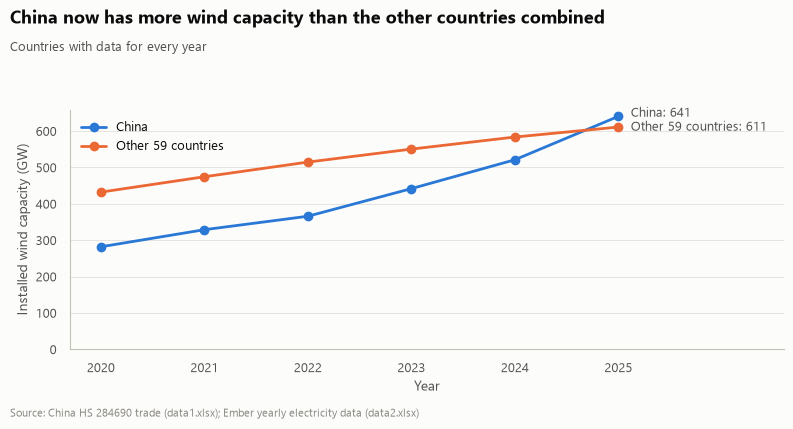

In [12]:
trend, info = ex.wind_trend(wind, focus="China")
display(trend)
title = {True: "China now has more wind capacity than the other countries combined",
         False: "Wind capacity keeps climbing, with China growing fastest",
         None: "Wind capacity keeps climbing"}[info["focus_ahead"]]
fig = ch.line_trend(trend, "year", info["series"], info["labels"], "Installed wind capacity (GW)",
                    title, "Countries with data for every year", SOURCE)
show(fig, "03_wind_trend")

### 2.4 Pairwise relationships

**Plots first, then the numbers.** Every correlation reported in this notebook is drawn in one of the two
charts below, so its shape (straight, curved, or driven by a few points) can be checked by eye before
any coefficient is read.

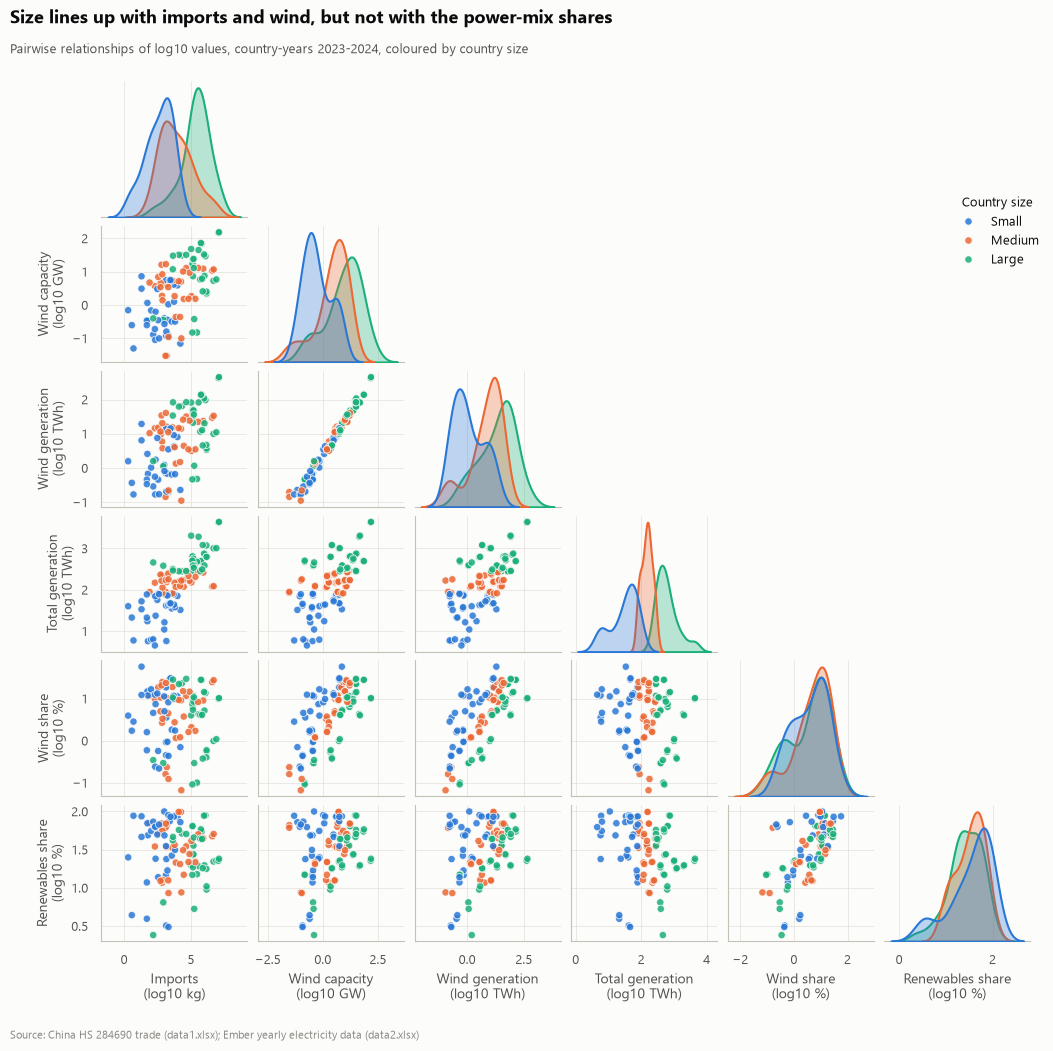

In [13]:
pair_cols = ["imports_from_china_kg", "wind_capacity_gw", "wind_generation_twh",
             "total_generation_twh", "wind_share_pct", "renewables_share_pct"]
fig = ch.pair_plot(
    sample, pair_cols,
    ["Imports\n(log10 kg)", "Wind capacity\n(log10 GW)", "Wind generation\n(log10 TWh)",
     "Total generation\n(log10 TWh)", "Wind share\n(log10 %)", "Renewables share\n(log10 %)"],
    "size_group", ex.SIZE_GROUPS,
    "Size lines up with imports and wind, but not with the power-mix shares",
    "Pairwise relationships of log10 values, country-years 2023-2024, coloured by country size",
    SOURCE, height=1.75)
show(fig, "08_pairplot")

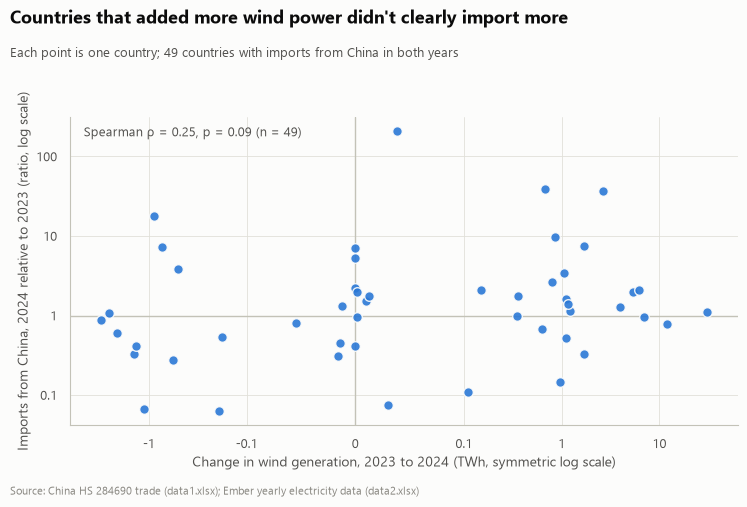

In [14]:
growth = ex.growth_vs_wind(panel, 2024)
h3 = st.correlation(growth, "import_growth_pct", "wind_generation_change_twh")
fig = ch.relationship_scatter(
    growth, "wind_generation_change_twh", "import_ratio",
    "Change in wind generation, 2023 to 2024 (TWh, symmetric log scale)",
    "Imports from China, 2024 relative to 2023 (ratio, log scale)",
    "Countries that added more wind power didn't clearly import more",
    f"Each point is one country; {len(growth)} countries with imports from China in both years",
    SOURCE, note=f"Spearman ρ = {h3['r']:.2f}, p = {h3['p']:.2f} (n = {h3['n']})",
    xscale="symlog", yscale="log", ref_x=0, ref_y=1)
show(fig, "10_growth_scatter")

In [15]:
pairs = [("imports_from_china_kg", "wind_capacity_gw"),
         ("imports_from_china_kg", "total_generation_twh"),
         ("wind_capacity_gw", "total_generation_twh"),
         ("imports_from_china_kg", "wind_share_pct")]
display(st.correlation_table(sample, pairs))
st.correlation_table(growth, [("import_growth_pct", "wind_generation_change_twh")])

,x,y,method,n,r,p,strength
0,imports_from_china_kg,wind_capacity_gw,spearman,102,0.52,0.00,moderate positive
1,imports_from_china_kg,total_generation_twh,spearman,102,0.76,0.00,strong positive
2,wind_capacity_gw,total_generation_twh,spearman,102,0.61,0.00,strong positive
3,imports_from_china_kg,wind_share_pct,spearman,102,-0.00,0.99,very weak


,x,y,method,n,r,p,strength
0,import_growth_pct,wind_generation_change_twh,spearman,49,0.25,0.09,weak positive


Reading the plots and the numbers together:
- **Imports rise with wind capacity** (ρ ≈ 0.5), but **even more with total electricity generation**
  (ρ ≈ 0.8), a measure of country size. In the pair plot, large countries (aqua) sit top-right in both.
- **Imports are unrelated to the share** of wind or renewables in the power mix: those panels are
  shapeless clouds, which is what ρ ≈ 0 means here.
- **Wind generation and wind capacity are nearly the same variable** (an almost straight line), so only
  capacity is used from here on.
- **Growth vs growth (2024)** is a weak positive correlation (ρ = 0.25). The scatter shows why it's weak:
  imports jump up and down by 10× or more whatever happened to wind. It isn't statistically
  significant, but the business gap isn't small either (see H3 in section 4).

---
## 3. Multivariate analysis

### 3.1 Correlation matrix

The same six measures as the pair plot in 2.4, so each coefficient here has its scatter panel there.

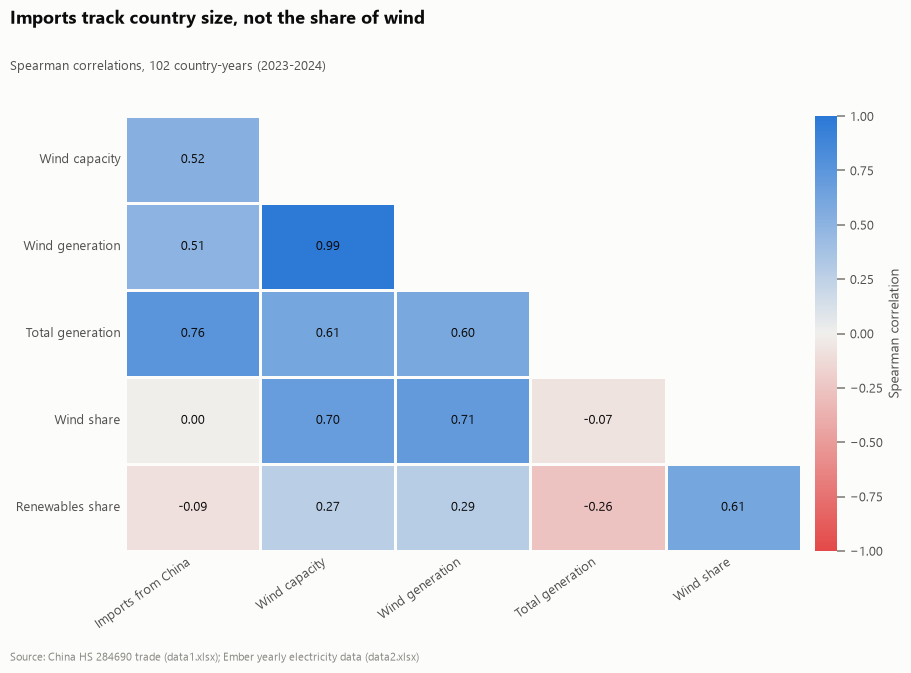

In [16]:
labels = ["Imports from China", "Wind capacity", "Wind generation", "Total generation",
          "Wind share", "Renewables share"]
matrix = st.correlation_matrix(sample, pair_cols)
fig = ch.correlation_heatmap(matrix, labels, "Imports track country size, not the share of wind",
                             f"Spearman correlations, {len(sample)} country-years (2023-2024)", SOURCE)
show(fig, "05_correlations")

### 3.2 Is the wind link just country size?

Larger economies use more electricity, build more wind **and** import more of everything. Partial
correlation and regression remove size (total generation) to see what wind adds on its own.

In [17]:
raw = st.correlation(sample, "imports_from_china_kg", "wind_capacity_gw")
partial = st.partial_correlation(sample, "imports_from_china_kg", "wind_capacity_gw",
                                 ["total_generation_twh"])
pd.DataFrame([raw, partial])[["x", "y", "n", "r", "p", "strength"]].assign(
    analysis=["raw (Spearman)", "size removed (partial, log10)"]).set_index("analysis")

,x,y,n,r,p,strength
analysis,,,,,,
raw (Spearman),imports_from_china_kg,wind_capacity_gw,102,0.52,0.00,moderate positive
"size removed (partial, log10)",imports_from_china_kg,wind_capacity_gw,102,0.13,0.19,very weak


In [18]:
wind_only = st.fit_log_ols(sample, "imports_from_china_kg", ["wind_capacity_gw"])
with_size = st.fit_log_ols(sample, "imports_from_china_kg", ["wind_capacity_gw", "total_generation_twh"])
print(f"Model A, wind only:   R2 = {wind_only.rsquared:.2f}, n = {int(wind_only.nobs)}")
display(st.tidy_coefficients(wind_only))
print(f"Model B, wind + size: R2 = {with_size.rsquared:.2f}, n = {int(with_size.nobs)}")
display(st.tidy_coefficients(with_size))
a, b, w = st.tidy_coefficients(wind_only), st.tidy_coefficients(with_size), "log_wind_capacity_gw"
print(f"Business reading, Model A: 10x the wind capacity goes with {st.fold_change(a.loc[w, 'coef']):.1f}x the imports")
print(f"Business reading, Model B: at the same size, 10x the wind capacity goes with "
      f"{st.fold_change(b.loc[w, 'coef']):.1f}x the imports (95% CI {st.fold_change(b.loc[w, 'ci_low']):.2f}x "
      f"to {st.fold_change(b.loc[w, 'ci_high']):.1f}x); 10x the size goes with "
      f"{st.fold_change(b.loc['log_total_generation_twh', 'coef']):.0f}x")

Model A, wind only:   R2 = 0.29, n = 102


,coef,std_err,p,ci_low,ci_high
term,,,,,
Intercept,3.46,0.20,0.00,3.06,3.85
C(year)[T.2024],0.32,0.15,0.03,0.03,0.60
log_wind_capacity_gw,0.94,0.17,0.00,0.61,1.27


Model B, wind + size: R2 = 0.58, n = 102


,coef,std_err,p,ci_low,ci_high
term,,,,,
Intercept,0.03,0.52,0.96,-1.00,1.05
C(year)[T.2024],0.24,0.14,0.09,-0.04,0.51
log_wind_capacity_gw,0.20,0.16,0.22,-0.12,0.52
log_total_generation_twh,1.74,0.25,0.00,1.26,2.22


Business reading, Model A: 10x the wind capacity goes with 8.7x the imports
Business reading, Model B: at the same size, 10x the wind capacity goes with 1.6x the imports (95% CI 0.76x to 3.3x); 10x the size goes with 55x


Both models use log10 values, so coefficients are **elasticities**, with standard errors clustered by
country and year fixed effects.
- **Model A:** a 1% larger wind fleet goes with about **0.9% more imports**: 10× the capacity, about
  9× the imports.
- **Model B:** once size is added, the wind elasticity falls to about **0.2** (95% CI −0.12 to 0.52).
  In business terms, at the same size 10× the wind capacity goes with about 1.6× the imports, and the
  data allow anything from 0.76× to 3.3×. That interval includes zero **and** effects large enough to
  matter, so the result is *inconclusive*, not proof that wind doesn't matter.
- Size carries most of the explanation (elasticity about **1.7**: 10× the size, about 55× the imports),
  and R² roughly doubles.

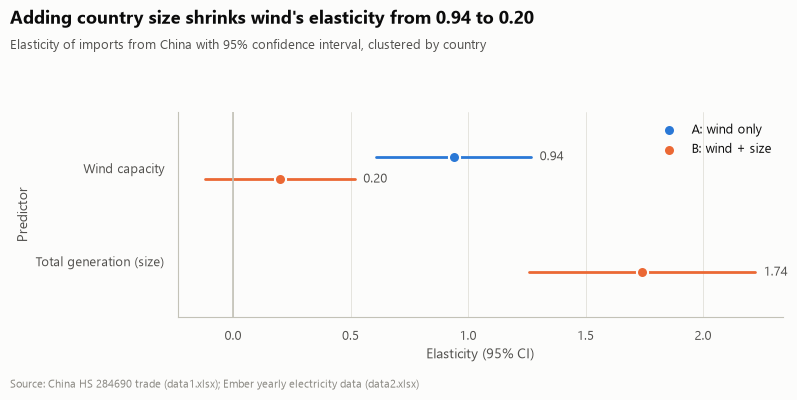

In [19]:
fig = ch.coefficient_plot(
    {"A: wind only": st.tidy_coefficients(wind_only), "B: wind + size": st.tidy_coefficients(with_size)},
    {"log_wind_capacity_gw": "Wind capacity", "log_total_generation_twh": "Total generation (size)"},
    f"Adding country size shrinks wind's elasticity from {a.loc[w, 'coef']:.2f} to {b.loc[w, 'coef']:.2f}",
    "Elasticity of imports from China with 95% confidence interval, clustered by country", SOURCE)
show(fig, "09_elasticities")

**Regression diagnostics (Model B).** Are the model's assumptions met?

In [20]:
st.regression_diagnostics(with_size)

,assumption,test,value,ok,meaning
0,Equal variance of residuals,Breusch-Pagan,0.85,True,no heteroskedasticity
1,Residuals normally distributed,Shapiro-Wilk,0.33,True,normal
2,Residuals normally distributed,Jarque-Bera,0.71,True,normal
3,No multicollinearity,max VIF (log_wind_capacity_gw),1.60,True,VIF < 5


All four checks pass:
- **Equal variance:** Breusch-Pagan (the regression form of Levene's test) finds no heteroskedasticity.
- **Normal residuals:** both Shapiro-Wilk and Jarque-Bera are consistent with normal residuals.
- **No collinearity:** wind capacity and size aren't so correlated that their effects can't be
  separated (VIF well below 5).

So the wide interval for wind isn't caused by a broken model or by collinearity: once size is in the
model, this data simply can't pin wind's own effect down.

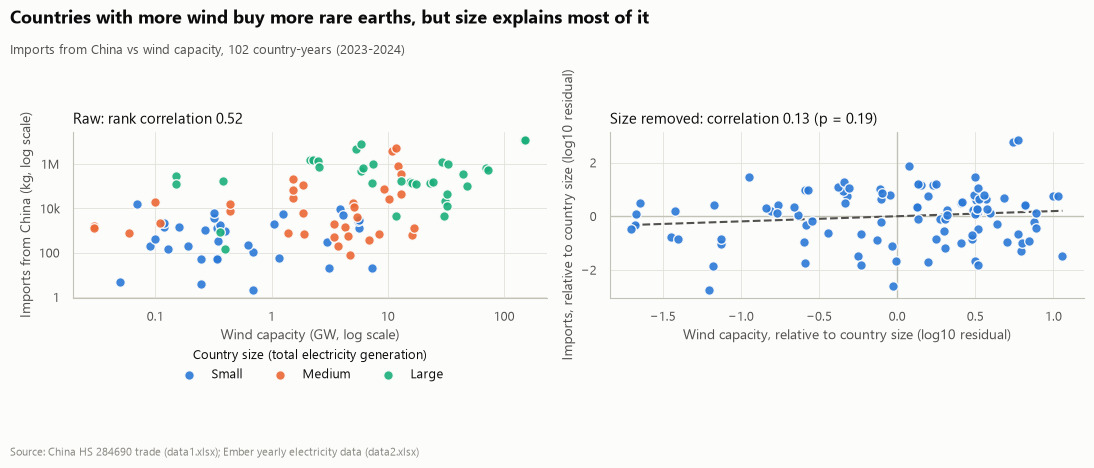

In [21]:
resid = st.size_adjusted_residuals(sample, "wind_capacity_gw", "imports_from_china_kg",
                                   ["total_generation_twh"])
fig = ch.confounding_scatter(
    sample, "wind_capacity_gw", "imports_from_china_kg", "size_group", ex.SIZE_GROUPS,
    resid, f"Raw: rank correlation {raw['r']:.2f}",
    f"Size removed: correlation {partial['r']:.2f} (p = {partial['p']:.2f})",
    "Countries with more wind buy more rare earths, but size explains most of it",
    f"Imports from China vs wind capacity, {len(sample)} country-years (2023-2024)", SOURCE,
    "Wind capacity (GW, log scale)", "Imports from China (kg, log scale)")
show(fig, "04_size_confound")

### 3.3 Missing years: do they change the result?

A pooled regression doesn't need every country in every year: each country-year is one row, and the
clustered standard errors allow for countries that appear once or twice. But a year with no recorded
imports can't be logged, so it drops out. Which partners skip years?

In [22]:
gaps = ex.import_year_pattern(panel, 2023, 2024)
display(gaps["pattern"].value_counts().to_frame("partners"))
skip = st.compare_groups(gaps, "typical_kg", "buyer_type", ["Every year", "Skipped a year"])
print(f"Typical recorded imports: {skip['medians']['Every year']:,.0f} kg for partners that buy every year, "
      f"{skip['medians']['Skipped a year']:,.0f} kg for partners that skipped a year "
      f"(Kruskal-Wallis p = {skip['p']:.1g})")
gaps[gaps["buyer_type"] == "Skipped a year"]

,partners
pattern,
Both years,52
2024 only,8
2023 only,8
Neither,4


Typical recorded imports: 15,892 kg for partners that buy every year, 212 kg for partners that skipped a year (Kruskal-Wallis p = 6e-06)


,kg_2023,kg_2024,pattern,buyer_type,typical_kg
partner,,,,,
Ecuador,NaN,"16,106.00",2024 only,Skipped a year,"16,106.00"
Cyprus,NaN,"1,450.00",2024 only,Skipped a year,"1,450.00"
Costa Rica,NaN,"1,000.00",2024 only,Skipped a year,"1,000.00"
Peru,NaN,"1,000.00",2024 only,Skipped a year,"1,000.00"
Bangladesh,NaN,800.00,2024 only,Skipped a year,800.00
"Egypt, Arab Rep.",690.00,NaN,2023 only,Skipped a year,690.00
Venezuela,350.00,NaN,2023 only,Skipped a year,350.00
Jordan,NaN,225.00,2024 only,Skipped a year,225.00
Nicaragua,200.00,NaN,2023 only,Skipped a year,200.00


A missing year is blank, never recorded as 0. The partners that skip a year are **small,
occasional buyers** (Bulgaria 2 kg, El Salvador 5 kg, Denmark 20 kg), so the gaps aren't random. A blank
most likely means China recorded no shipment that year, but the data can't confirm a true zero.

**Robustness check.** Model B is re-estimated on only the countries that bought in both years, and with
**PPML** (Poisson pseudo-maximum likelihood, the standard model for trade flows), which keeps the missing
years as 0 kg instead of dropping them.

In [23]:
drivers = ["wind_capacity_gw", "total_generation_twh"]
both_years = st.fit_log_ols(ex.balanced_panel(sample), "imports_from_china_kg", drivers)
ppml = st.fit_ppml(ex.analysis_sample(panel, include_non_buyers=True), "imports_from_china_kg", drivers)
st.compare_models({"B: all buyers (log-log OLS)": with_size, "B: buyers in both years only": both_years,
                   "PPML: missing years as 0 kg": ppml}, ["log_wind_capacity_gw", "log_total_generation_twh"])

,model,term,n,coef,ci_low,ci_high,p,fold_10x
0,B: all buyers (log-log OLS),log_wind_capacity_gw,102,0.20,-0.12,0.52,0.22,1.58
1,B: all buyers (log-log OLS),log_total_generation_twh,102,1.74,1.26,2.22,0.00,55.16
2,B: buyers in both years only,log_wind_capacity_gw,88,0.15,-0.15,0.46,0.33,1.42
3,B: buyers in both years only,log_total_generation_twh,88,2.03,1.47,2.59,0.00,106.85
4,PPML: missing years as 0 kg,log_wind_capacity_gw,116,0.14,-0.33,0.60,0.57,1.37
5,PPML: missing years as 0 kg,log_total_generation_twh,116,1.05,0.18,1.93,0.02,11.34


In [24]:
print("Share of the variation that is within a country, over time (log10):")
for col in ["wind_capacity_gw", "total_generation_twh", "imports_from_china_kg"]:
    print(f"  {col}: {st.within_share(sample, col):.1%}")

Share of the variation that is within a country, over time (log10):
  wind_capacity_gw: 0.1%
  total_generation_twh: 0.0%
  imports_from_china_kg: 4.5%


**The conclusion doesn't depend on how the missing years are handled.** In all three models wind's
elasticity stays small (0.14–0.20) and not significant, and size stays large and significant. PPML's size
elasticity is lower (about 1.1) because it gives more weight to the largest importers; the log model
weights every country equally.

**Two models the data can't support yet:**
- **Country fixed effects** use only each country's change over time. Almost none of the variation in
  wind capacity (0.1%) or size is within a country over two years, so the estimate would rest on almost
  no information.
- **ARIMA** forecasts one country's series from its own past. It needs a long, evenly spaced series
  (around 50 points as a rule of thumb); each country has at most two annual points, and the small buyers
  have gaps. **Monthly** trade data for 2020–2025 (72 points) would make it possible for the large,
  steady buyers.

---
## 4. Hypothesis testing

Five hypotheses, in three steps:
1. **Check each test's assumptions** (Shapiro-Wilk, Levene) and pick the test they allow (4.1).
2. **Report the business magnitude and the effect size first**, then the p-value (4.2).
3. **Judge statistical and business significance separately** (4.3).

Because five tests are run, p-values are **Holm-adjusted** to keep the overall chance of a false
positive at 5%.

### 4.1 Assumption checks

In [25]:
order = ex.SIZE_GROUPS
print("H5 (Kruskal-Wallis): imports by size group, raw kg")
display(st.group_assumptions(sample, "imports_from_china_kg", "size_group", order))
print("H5: the same on log10 kg")
st.group_assumptions(sample, "imports_from_china_kg", "size_group", order, log=True)

H5 (Kruskal-Wallis): imports by size group, raw kg


,check,test,scale,n,statistic,p,ok
0,Normal within Small,Shapiro-Wilk,raw,34,0.63,0.00,False
1,Normal within Medium,Shapiro-Wilk,raw,34,0.33,0.00,False
2,Normal within Large,Shapiro-Wilk,raw,34,0.50,0.00,False
3,Equal variances across groups,Levene (median-centred),raw,102,5.10,0.01,False


H5: the same on log10 kg


,check,test,scale,n,statistic,p,ok
0,Normal within Small,Shapiro-Wilk,log10,34,0.95,0.14,True
1,Normal within Medium,Shapiro-Wilk,log10,34,0.95,0.09,True
2,Normal within Large,Shapiro-Wilk,log10,34,0.93,0.04,False
3,Equal variances across groups,Levene (median-centred),log10,102,0.69,0.51,True


In [26]:
exports = trade[trade["trade_flow"] == "Export"]
price_ratios = st.paired_log_ratios(exports, "partner", "year", "unit_value_usd_per_kg", 2023, 2024)
pd.DataFrame([st.normality_test(price_ratios), st.normality_test(resid["x_resid"]),
              st.normality_test(resid["y_resid"])],
             index=["H4: per-buyer price change (log ratio)", "H2: wind capacity, size removed",
                    "H2: imports, size removed"])

,test,scale,n,statistic,p,skew,normal
H4: per-buyer price change (log ratio),Shapiro-Wilk,raw,52,0.84,0.00,-1.53,False
"H2: wind capacity, size removed",Shapiro-Wilk,raw,102,0.93,0.00,-0.76,False
"H2: imports, size removed",Shapiro-Wilk,raw,102,0.98,0.16,-0.17,True


In [27]:
h2_ranks = st.partial_correlation(sample, "imports_from_china_kg", "wind_capacity_gw",
                                 ["total_generation_twh"], method="spearman")
h4_all = st.paired_change(exports, "partner", "year", "unit_value_usd_per_kg", 2023, 2024, test="sign")
print(f"H2 check without normality (rank-based partial correlation): r = {h2_ranks['r']:.2f}, p = {h2_ranks['p']:.2f}")
print(f"H4 p-values: sign test {h4_all['sign_p']:.3f}, Wilcoxon {h4_all['wilcoxon_p']:.3f}, "
      f"paired t-test {h4_all['t_test_p']:.3f} (not valid here)")

H2 check without normality (rank-based partial correlation): r = 0.12, p = 0.24
H4 p-values: sign test 0.126, Wilcoxon 0.073, paired t-test 0.045 (not valid here)


**What the checks found, and what they change**

| Hypothesis and test | Assumption | Finding | Consequence |
|---|---|---|---|
| H1, H3: Spearman correlation | A monotonic relationship (no normality needed) | The scatters in 2.4 show straight-line or shapeless patterns, with no curve hiding a relationship | Spearman is appropriate |
| H2: partial correlation on log10 | Normal residuals | Imports residual normal (Shapiro p = 0.16); wind residual **not** normal (p < 0.001) | Checked with a rank-based partial correlation: r = 0.12, p = 0.24, the same conclusion. Model B's residuals are normal (3.2) |
| H4: paired price change | t-test: normal changes. Wilcoxon: symmetric changes | Log price changes are **not normal** (Shapiro p < 0.001) and **skewed** (−1.5): a few buyers had very large falls | Neither test is safe, so H4 uses the **sign test**, which only counts rises and falls. A paired t-test would have given p = 0.045, a false "significant" |
| H5: Kruskal-Wallis across size groups | Similar spread in each group | Raw kg: not normal in any group, and **unequal variances** (Levene p = 0.008). Log10 kg: **equal variances** (Levene p = 0.51); normal in small and medium groups, borderline in large (p = 0.04) | Kruskal-Wallis needs no normality, and with equal spreads on the log scale its result reads as a shift in typical imports between groups |

### 4.2 Business magnitude and effect size, then p-values

In [28]:
tests = st.main_hypothesis_tests(sample, growth, exports, order)
tests

,hypothesis,magnitude,effect_measure,effect_size,effect,test,n,statistic,p,p_holm,statistically_significant,result
0,H1: imports rise with wind capacity,"10x the wind capacity, 8.7x the imports",Spearman rho,0.52,moderate positive,Spearman correlation,102,0.52,0.00,0.00,True,Supported
1,H2: wind matters after controlling for size,"Same size, 10x the wind: 1.6x the imports (95%...",partial r,0.13,very weak,Partial correlation (log10),102,0.13,0.19,0.26,False,Not supported
2,"H3: faster wind growth, faster import growth (...",Median import growth +50% where wind grew most...,Spearman rho,0.25,weak positive,Spearman correlation,49,0.25,0.09,0.26,False,Not supported
3,H4: buyers paid less per kg in 2024 than 2023,Median buyer -11% (95% CI -26% to +4%); 62% pa...,rank-biserial r,-0.29,weak negative,Sign test (paired),52,32.00,0.13,0.26,False,Not supported
4,H5: imports differ by country size,Large countries' median imports 325x small cou...,epsilon-squared,0.50,large,Kruskal-Wallis,102,50.58,0.00,0.00,True,Supported


In [29]:
h5 = st.compare_groups(sample, "imports_from_china_kg", "size_group", order)
print("H5 medians (kg):", {k: f"{v:,.0f}" for k, v in h5["medians"].items()})
ci = st.bootstrap_ci(ex.buyer_volumes(trade, 2024), st.top_share)
print(f"Top-5 buyers' share of 2024 exports: {ci['estimate']:.1%} "
      f"(95% bootstrap CI {ci['ci_low']:.1%} to {ci['ci_high']:.1%})")

H5 medians (kg): {'Small': '705', 'Medium': '5,040', 'Large': '229,432'}
Top-5 buyers' share of 2024 exports: 83.1% (95% bootstrap CI 60.7% to 91.3%)


### 4.3 Statistical significance is not business significance

A p-value only says whether an effect can be told apart from zero with this much data. Whether it
**matters** depends on its size. The thresholds below are the analyst's judgement, stated so they can be
challenged:
- **Prices:** a change of **5% or more** in the price per kg is material for a buyer's budget or contract.
- **Demand drivers:** a driver is material for forecasting if 10× the driver goes with at least
  **2× the imports** (an elasticity of 0.3 or more).

| | Statistically significant? (Holm p) | Business magnitude | Business significance |
|---|---|---|---|
| **H1** | Yes (p < 0.001) | 10× wind, 8.7× imports | Large, but **misleading on its own**: it is mostly country size (H2) |
| **H2** | No (p = 0.26) | Same size, 10× wind: 1.6× imports (0.76× to 3.3×) | **Inconclusive.** The estimate is below the 2× threshold, but the interval includes effects up to 3.3×. Not evidence that wind doesn't matter |
| **H3** | No (p = 0.26) | Median import growth +50% where wind grew most, −11% elsewhere | **Would matter if real**, but one year and 49 countries can't confirm it. Retest with more years |
| **H4** | No (p = 0.26) | Median buyer −11% (−26% to +4%); at fixed volumes −35% | **Material.** The 35% fixed-basket fall (2.2) is measured on China's whole export trade, not estimated from a sample. What isn't established is a cut for the *typical*, mostly small, buyer |
| **H5** | Yes (p < 0.001) | Large countries import 325× small ones | **Material:** size is the main demand driver |

**Results**
- **H1 and H5 are supported**, with large effects (ρ = 0.52; ε² = 0.50).
- **H2, H3 and H4 are not statistically significant**, but none of them shows that the effect is zero
  or unimportant. H2's interval still allows a material wind effect, H3's gap would matter if it holds,
  and the 2024 price fall was real and large for the biggest buyers (2.2).
- **Concentration:** even the lower end of the bootstrap interval shows the top five buyers above 60%.

### 4.4 Regression check: each hypothesis as a log-log OLS

Each hypothesis is re-tested as a regression, with its residuals checked. H1, H2 and H5 come from
Models A and B (3.2). H3 becomes a regression in **changes** (log of 2024 / 2023), which compares each
country with itself; H4 becomes the mean log price change. Plot first: H3's change regression.

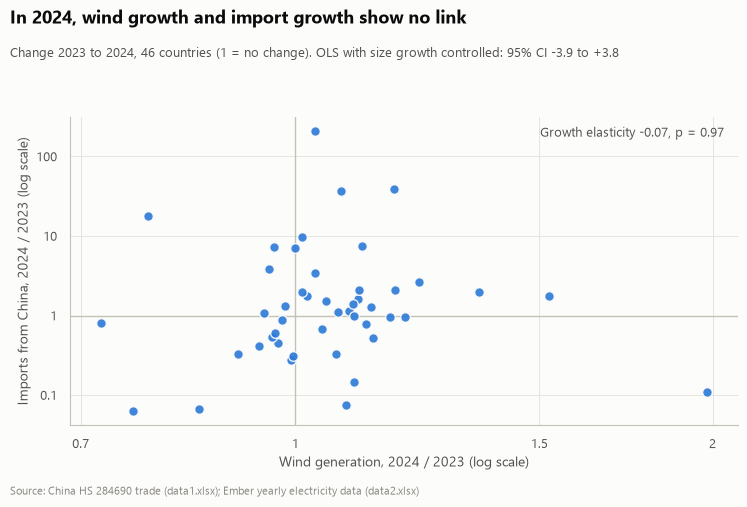

In [30]:
growth_model = st.fit_log_change_ols(panel, "imports_from_china_kg", ["wind_generation_twh", "total_generation_twh"],
                                     "country", "year", 2023, 2024)
h3_ols = st.coefficient_evidence(growth_model, "dlog_wind_generation_twh", factor=2)
changes = st.log_changes(panel, ["imports_from_china_kg", "wind_generation_twh", "total_generation_twh"],
                         "country", "year", 2023, 2024)
fig = ch.relationship_scatter(
    changes, "ratio_wind_generation_twh", "ratio_imports_from_china_kg",
    "Wind generation, 2024 / 2023 (log scale)", "Imports from China, 2024 / 2023 (log scale)",
    "In 2024, wind growth and import growth show no link",
    f"Change 2023 to 2024, {len(changes)} countries (1 = no change). OLS with size growth controlled: "
    f"95% CI {h3_ols['ci_low']:+.1f} to {h3_ols['ci_high']:+.1f}", SOURCE,
    note=f"Growth elasticity {h3_ols['coef']:+.2f}, p = {h3_ols['p']:.2f}",
    xscale="log", yscale="log", ref_x=1, ref_y=1, note_loc="upper right")
show(fig, "11_growth_elasticity")

In [31]:
regression_check = st.regression_hypothesis_checks(sample, panel, exports)
regression_check.assign(main_test_result=tests["result"].to_numpy())[
    ["hypothesis", "magnitude", "effect_size", "test", "n", "p", "p_holm", "residual_shapiro_p",
     "result", "main_test_result"]]

,hypothesis,magnitude,effect_size,test,n,p,p_holm,residual_shapiro_p,result,main_test_result
0,H1: imports rise with wind capacity,"10x the wind, 8.7x the imports (4.1x to 18.6x)",0.94,"Log-log OLS, wind only (Model A)",102,0.00,0.00,0.44,Supported,Supported
1,H2: wind matters after controlling for size,"Same size, 10x the wind: 1.6x the imports (0.7...",0.20,"Log-log OLS, wind + size (Model B)",102,0.22,0.44,0.33,Not supported,Not supported
2,"H3: faster wind growth, faster import growth (...",Doubling wind output: 0.96x the import growth ...,-0.07,"OLS in log changes, size growth controlled",46,0.97,0.97,0.08,Not supported,Not supported
3,H4: buyers paid less per kg in 2024 than 2023,Mean buyer -31% (-52% to -2%),-0.37,OLS of log price change on a constant (= paire...,52,0.04,0.12,0.00,Not supported,Not supported
4,H5: imports differ by country size,"Same wind, 10x the size: 55x the imports (18x ...",1.74,"Log-log OLS, wind + size (Model B)",102,0.00,0.00,0.33,Supported,Supported


**The regressions agree with the main tests (4.2) on every hypothesis.**
- **H1 and H5 are supported**, with normal residuals. 10× the wind goes with about 9× the imports on its
  own; at the same wind, 10× the size goes with about 55×.
- **H2 isn't supported** (Holm p = 0.44): at the same size, wind's elasticity is 0.20.
- **H3 isn't supported.** In growth terms, wind growth predicts nothing (elasticity about −0.07), and the
  interval is so wide that the data can't tell. The Spearman test in 4.2 used the change in TWh, which is
  larger for big countries, so its weak positive link probably reflects size.
- **H4 shouldn't be judged by OLS.** Its p = 0.04 looks significant, but the residuals are far from
  normal (Shapiro-Wilk p < 0.001): this is the paired t-test that 4.1 rejected. It isn't significant
  after the Holm correction anyway, and the sign test stays the right test.

A regression can't *prove* a hypothesis. It shows how unlikely the data would be without a relationship,
and with two years of observational data that is an association, not a causal effect.

---
## 5. Findings that inform the modeling approach

| # | Finding | Implication for modeling (Assignment 6) |
|---|---|---|
| 1 | All size measures are skewed 4–7 | Model **log** quantities; report elasticities |
| 2 | Wind capacity's link with imports is mostly **country size** | Always **control for size** (total generation; add GDP if available); wind alone overstates its effect |
| 3 | Imports are unrelated to the wind **share** of the power mix | Use absolute capacity or capacity **additions**, not shares |
| 4 | Growth rates explode from small bases (mean in the thousands of %) | Model growth as a **log ratio**, or set a minimum base |
| 5 | Imports exist only for 2023–2024 | Re-download `data1.xlsx` with exports for all years before panel or time-series models; for now n = 102 country-years in a cross-section. Country fixed effects and ARIMA need more years; ARIMA needs **monthly** data |
| 6 | Price per kg varies more than 1,000-fold within HS 284690 | Use **kg** as the demand measure; treat value separately |
| 7 | Five buyers hold over 80% of volume | Check that results don't hinge on the US and Japan (re-estimate without them) |
| 8 | The 2024 price fall is a price fall, not mix: −35% at fixed volumes, led by Japan | Model prices per buyer (or grade); separate price from mix; check robustness without Japan |
| 9 | Assumptions checked: log imports have equal variances across size groups (Levene) and Model B passes Breusch-Pagan, Shapiro-Wilk, Jarque-Bera and VIF; price changes are skewed | Log-log OLS with clustered errors is a sound baseline; use sign or rank tests for price changes |
| 10 | H2 and H3 aren't statistically significant but can't rule out effects that would matter | Get more years before concluding "no effect"; report intervals and business magnitudes, not just p-values |
| 11 | 16 partners bought in only one of the two years; they are tiny buyers | Pooled OLS handles the gaps; re-estimate without them and with **PPML** (missing = 0). Both give the same conclusion |
| 12 | Every hypothesis re-tested as a regression gives the same verdict (4.4) | Use **log-log OLS** as the baseline model; keep sign or rank tests for skewed price changes |

Full write-up: [`docs/statistical_analysis_report.md`](../docs/statistical_analysis_report.md). Executive summary:
[`docs/executive_summary.md`](../docs/executive_summary.md).